# Динамическое ценообразование авиабилетов - ML-часть кейса

В ML-части кейса вы научитесь работать с данными с помощью **pandas**, обучать модели прогнозирования временных рядов
с помощью **AutoGluon** и честно проверять их качество.

## Постановка задачи

Мы хотим выставлять на авиабилеты разные цены в зависимости от ситуации, чтобы получать наибольшую прибыль. Для этого
нужно понимать, сколько людей захотят купить билет по нашей цене. Поэтому мы будем прогнозировать **спрос при базовой
цене**: сколько человек захотят полететь в конкретный день, если билет стоит как обычно.

Будем считать, что у людей есть **чувствительность к цене (эластичность)**: если поднять цену на N рублей, часть
желающих откажется от покупки. Наши аналитики уже посчитали эти значения для каждого маршрута. Ещё при подборе цены
нужно помнить, что **мест в самолёте ограниченное количество**, и продать билеты абсолютно всем желающим мы не можем.

Будущее сложно предсказать точно, поэтому моделью мы будем предсказывать не одно число, а **квантили** - прогнозы для разных сценариев.

**Квантиль q** - это значение, ниже которого настоящий спрос окажется с вероятностью q:
- **квантиль 0.1** - пессимистичный сценарий: спрос окажется ниже этого числа только в 10% случаев, а в 90% - выше;
- **квантиль 0.5 (медиана)** -  спрос с равной вероятностью окажется выше или ниже;
- **квантиль 0.9** - оптимистичный сценарий: спрос превысит это число только в 10% случаев.

Например, для рейса Москва - Сочи на 12 июня модель может выдать:

| квантиль | 0.1 | 0.3 | 0.5 | 0.7 | 0.9 |
|---|---|---|---|---|---|
| спрос, человек | 744 | 830 | 888 | 946 | 1032 |

Из квантилей строятся **интервалы**. Диапазон от квантиля 0.1 до квантиля 0.9 - это **80%-й интервал**: с вероятностью
80% настоящий спрос окажется между 744 и 1032. Чем шире интервал, тем меньше модель уверена в прогнозе.

Для бизнеса важно получить не одну цену, а **распределение цены**, чтобы понимать, насколько модель уверена. Если разброс
цен слишком большой, на ситуацию стоит взглянуть дополнительно и выбрать менее рискованный вариант.

Для каждого сценария спроса можно посчитать свою лучшую цену: чем больше спрос, тем выше цена. Так из квантилей спроса
получается **распределение цены**, которое и нужно бизнесу.

## Данные

**`train.csv`** - история спроса с 1 января 2022 по 30 апреля 2026, на ней обучаем модели.
**`test.csv`** - спрос за май 2026, только для финальной проверки выбранной модели.

| колонка | что означает |
|---|---|
| `date` | дата рейса |
| `route` | код маршрута, например `MOW-AER` (Москва - Сочи) |
| `demand` | спрос: сколько человек купили бы билет в этот день по базовой цене |

**`routes.csv`** - справочник маршрутов:

| колонка | что означает |
|---|---|
| `route` | код маршрута |
| `name` | города, например Москва - Сочи |
| `base_price` | базовая цена билета, ₽ |
| `cost_per_passenger` | наши расходы на одного пассажира, ₽ |
| `price_sensitivity` | чувствительность к цене: сколько пассажиров теряем на каждый +1 ₽ цены |
| `price_min`, `price_max` | допустимый диапазон цены, ₽ |

**`schedule.csv`** - расписание на май–июль 2026:

| колонка | что означает |
|---|---|
| `date` | дата рейса |
| `route` | код маршрута |
| `seats` | сколько всего мест в самолётах на этом маршруте в этот день |

## Как работать

Если непонятно, как устроена функция или метод, загляните в документацию: [pandas](https://pandas.pydata.org/docs/),
[AutoGluon](https://auto.gluon.ai/stable/tutorials/timeseries/index.html), [matplotlib](https://matplotlib.org/stable/).
Можно спросить и у ИИ-ассистента, но не злоупотребляйте: важно, чтобы вы понимали, что вы делаете.

Описание любой функции можно посмотреть прямо в ноутбуке: поставьте `?` после её названия и запустите ячейку.
Пример - в ячейке ниже.

In [ ]:
import pandas as pd

pd.read_csv?

## Подготовка

Запустите ячейку ниже. В Google Colab она установит AutoGluon и скачает данные кейса - это займёт несколько минут.
Если после установки Colab попросит перезапустить сеанс (Restart session), перезапустите и запустите эту ячейку ещё раз.

In [ ]:
import os, sys, zipfile, urllib.request

IN_COLAB = "google.colab" in sys.modules
LOCAL_DATA = "../../data/ml_case/public/"                    # путь к данным при запуске из репозитория кейса

if IN_COLAB:
    !uv pip install autogluon.timeseries --extra-index-url https://download.pytorch.org/whl/cpu   # в Colab AutoGluon не установлен

if IN_COLAB or not os.path.exists(LOCAL_DATA):
    url = "https://gist.githubusercontent.com/Murkat-git/3ddc868889d3e0d37542d786c8b1aa74/raw/reshis_case_data.zip"
    urllib.request.urlretrieve(url, "reshis_case_data.zip")                  # скачиваем архив с данными
    zipfile.ZipFile("reshis_case_data.zip").extractall()                    # распаковываем в папку data/
    DATA_DIR = "data/"
else:
    DATA_DIR = LOCAL_DATA

print("Запуск в Colab" if IN_COLAB else "Запуск на своём компьютере", "- данные в папке", DATA_DIR)

Using Python 3.13.18 environment at: /usr
Resolved 123 packages in 2.51s
Prepared 33 packages in 1m 16s
Uninstalled 4 packages in 1.10s
Installed 33 packages in 594ms
 + adagio==0.2.6
 + alembic==1.20.1
 + autogluon-common==1.6.3
 + autogluon-core==1.6.3
 + autogluon-features==1.6.3
 + autogluon-tabular==1.6.3
 + autogluon-timeseries==1.6.3
 + boto3==1.44.3
 + botocore==1.44.3
 + catboost==1.2.10
 + chronos-forecasting==2.3.2
 + colorlog==6.12.0
 + coreforecast==0.0.16
 + fugue==0.9.9
 + gluonts==0.17.0
 + jmespath==1.1.0
 + lightning==2.6.6
 + lightning-utilities==0.11.8
 + mako==1.4.3
 + mlforecast==0.14.0
 + optuna==5.0.0
 - peft==0.21.2
 + peft==0.19.1
 + pytorch-lightning==2.6.6
 + s3transfer==0.19.3
 + statsforecast==2.0.1
 - tokenizers==0.23.3
 + tokenizers==0.22.2
 - torch==2.14.1+cpu (from https://download.pytorch.org/whl/cpu/torch-2.14.1%2Bcpu-cp313-cp313-manylinux_2_28_x86_64.whl)
 + torch==2.13.0+cpu
 + torchmetrics==1.0.3
 - transformers==5.22.1
 + transformers==5.14.1
 + 

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv(DATA_DIR + "train.csv", parse_dates=["date"])
test = pd.read_csv(DATA_DIR + "test.csv", parse_dates=["date"])
routes = pd.read_csv(DATA_DIR + "routes.csv")
routes.head()

,route,name,base_price,cost_per_passenger,price_sensitivity,price_min,price_max
0,MOW-AER,Москва — Сочи,9000,4200,0.1410,5400,18000
1,MOW-LED,Москва — Санкт-Петербург,5500,2600,0.2940,3300,11000
2,MOW-KGD,Москва — Калининград,7500,3500,0.0957,4500,15000
3,MOW-OVB,Москва — Новосибирск,12000,6000,0.0312,7200,24000
4,MOW-MRV,Москва — Минеральные Воды,8000,3800,0.0653,4800,16000


## Задание 1. Исследование данных

**1.1.** Посмотрите на данные глазами: постройте графики изменения спроса по датам для каждого маршрута. Вам может помочь
метод `.plot()` у pandas DataFrame или функции из matplotlib / seaborn.

**1.2.** Видите ли вы в данных что-то необычное? Резкие скачки, провалы, изменения уровня? Как вы думаете, это шум или
что-то полезное для модели? Подумайте, что могло происходить в такие дни: это поможет на следующих этапах.

**Результат задания:** графики спроса по каждому маршруту и текстовый ответ: что необычного вы нашли в данных и что,
по-вашему, происходило в эти дни.

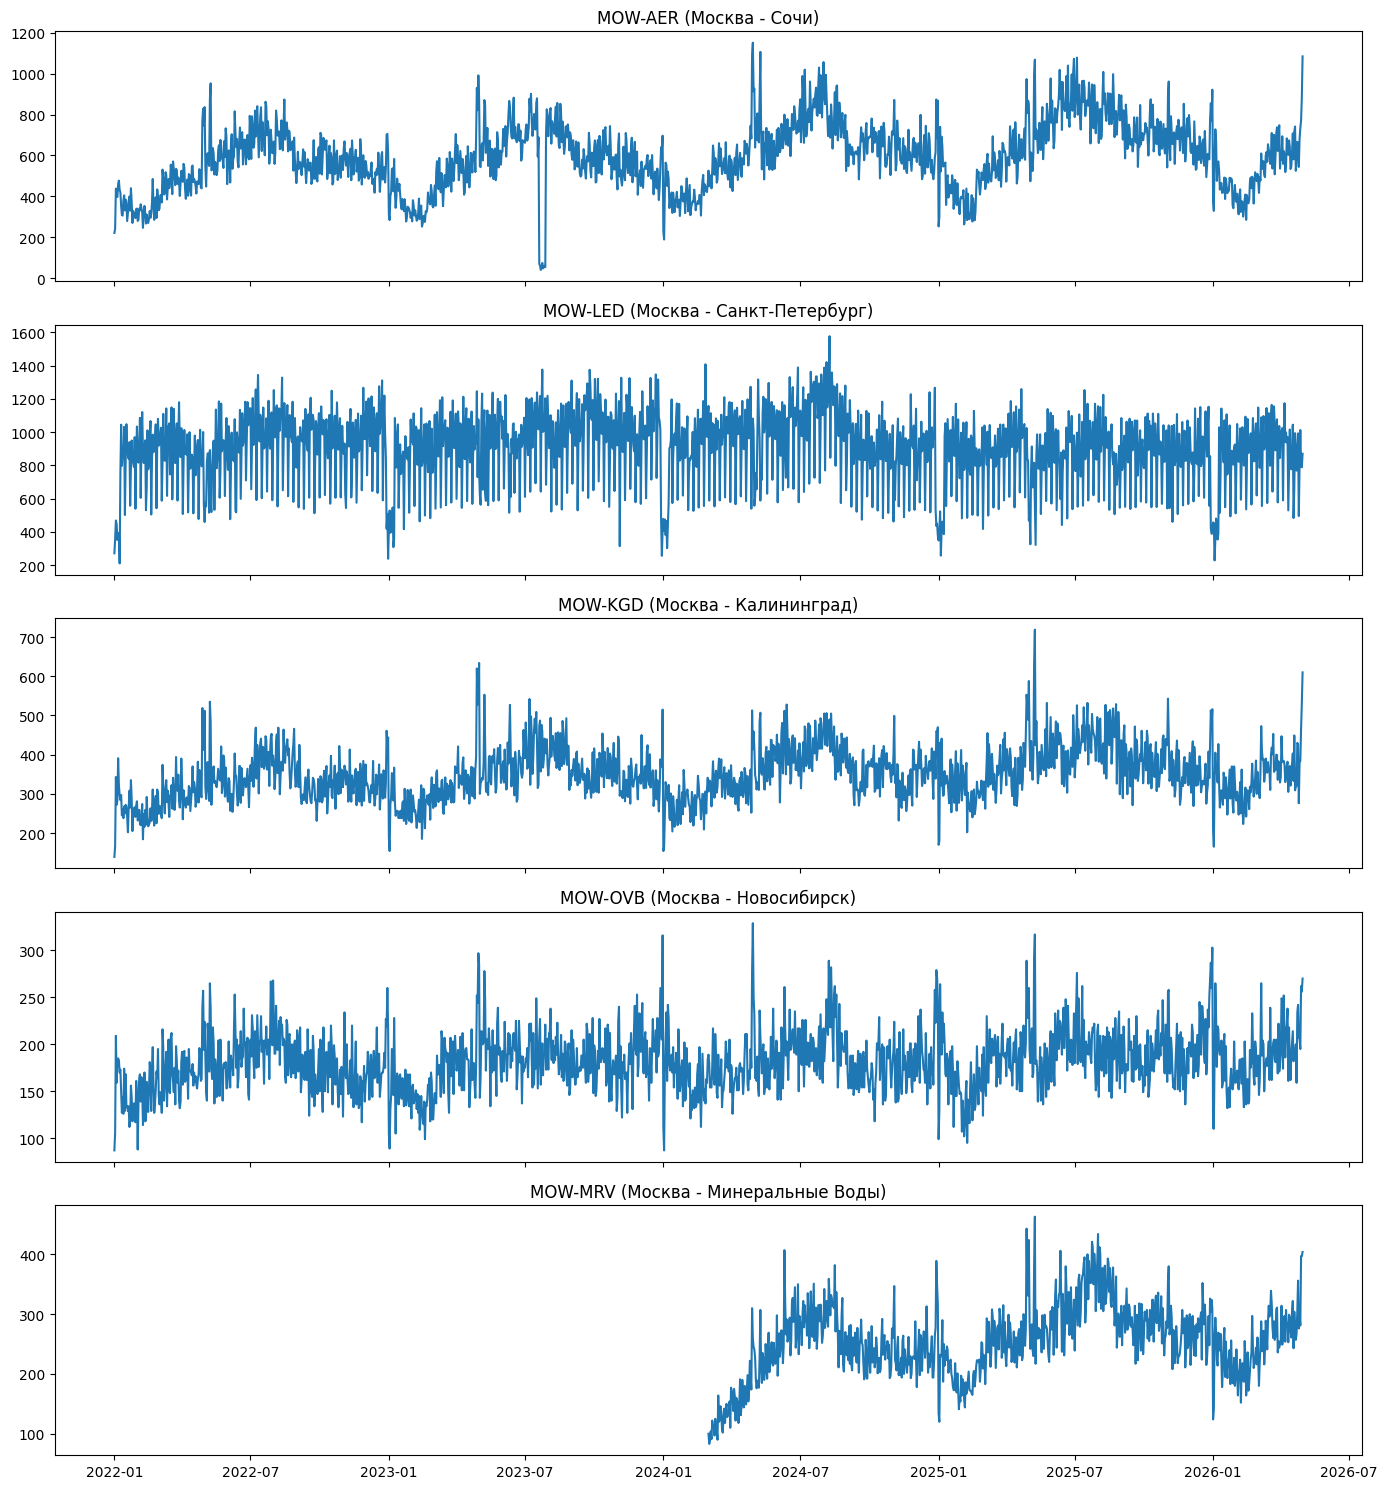

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(14, 15), sharex=True)



g1 = train[train["route"] == "MOW-AER"]
axes[0].plot(g1["date"], g1["demand"])
axes[0].set_title("MOW-AER (Москва - Сочи)")

g2 = train[train["route"] == "MOW-LED"]
axes[1].plot(g2["date"], g2["demand"])
axes[1].set_title("MOW-LED (Москва - Санкт-Петербург)")

g3 = train[train["route"] == "MOW-KGD"]
axes[2].plot(g3["date"], g3["demand"])
axes[2].set_title("MOW-KGD (Москва - Калининград)")

g4 = train[train["route"] == "MOW-OVB"]
axes[3].plot(g4["date"], g4["demand"])
axes[3].set_title("MOW-OVB (Москва - Новосибирск)")

g5 = train[train["route"] == "MOW-MRV"]
axes[4].plot(g5["date"], g5["demand"])
axes[4].set_title("MOW-MRV (Москва - Минеральные Воды)")

plt.tight_layout()
plt.show()


**Ваш ответ:** Что необычного вы нашли в данных? Это шум или что-то полезное для модели? Что, по-вашему, происходило в эти дни?

Четкая годовая сезонность

Регулярные резкие провали и скачки (После нового года спрос падает, а на майских каникулах резкие скачки)

Разовая аномалия в Сочи

Короткая история у Минеральных Вод

## Задание 2. Обучение моделей в AutoGluon

[AutoGluon](https://auto.gluon.ai/stable/tutorials/timeseries/index.html) - библиотека, которая умеет обучать сразу много
моделей прогнозирования временных рядов и сравнивать их между собой. Подробнее - в
[быстром старте](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-quick-start.html).

Шпаргалка по основным вызовам (из документации AutoGluon):

```python
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

# 1) данные: длинная таблица - по строке на каждый ряд и момент времени
data = TimeSeriesDataFrame.from_data_frame(df, id_column="item_id", timestamp_column="timestamp")

# 2) предиктор
predictor = TimeSeriesPredictor(
    prediction_length=48,              # на сколько шагов вперёд прогнозировать
    target="target",                   # какую колонку прогнозируем
    eval_metric="MASE",                # как считаем ошибку
    quantile_levels=[0.1, 0.5, 0.9],   # какие квантили выдавать
    path="autogluon-models",           # куда сохранять модели
)

# 3а) обучение готовым набором моделей - пресетом
predictor.fit(data, presets="medium_quality", time_limit=600)

# 3б) или списком конкретных моделей с параметрами
predictor.fit(data, hyperparameters={
    "SeasonalNaive": {},
    "DirectTabular": {},
    "Chronos": {"model_path": "bolt_small"},
})

# 4) таблица моделей: ошибка на валидации (score_val), время обучения и прогноза
predictor.leaderboard()

# 5) прогноз и график: история + прогноз с квантилями
predictions = predictor.predict(data)
predictor.plot(data, predictions, quantile_levels=[0.1, 0.9], max_history_length=200)

# 6) ошибка на тестовых данных (история + последние prediction_length шагов для проверки)
predictor.evaluate(test_data)
```

На что обратить внимание:
- **Длина прогноза.** Выберите её сами, исходя из длины тестовых данных.
- **Метрика.** Ошибку считаем по **MAE** (средняя абсолютная ошибка: на сколько пассажиров в среднем промахивается прогноз).
- **Квантили.** Модель должна выдавать квантили от 0.1 до 0.9: из них потом получится распределение цены.
- **Валидация.** AutoGluon сам откладывает последние дни обучающих данных как валидацию и сравнивает модели по ним.
  Тест (`test.csv`) пока **не трогаем**: он понадобится в самом конце.
- **Какие модели обучать.** Пресет - быстрый способ начать; список моделей и параметров даёт больше контроля.
  Какие есть пресеты и модели, смотрите в
  [описании моделей](https://auto.gluon.ai/stable/tutorials/timeseries/forecasting-model-zoo.html).

**2.1.** Обучите модели на `train`. Поэкспериментируйте с разными конфигурациями обучения (пресеты, наборы моделей,
их параметры) и выберите **конфигурацию**, которая даёт наименьшую ошибку на валидации.

**2.2.** Посмотрите на таблицу моделей (`leaderboard`) для выбранной конфигурации. Какая модель лучшая по валидации?
Как вы думаете, почему именно, как она работает? Насколько она лучше самой простой - `SeasonalNaive` (как в прошлом сезоне)?

**Результат задания:** обученные модели и таблица моделей (`leaderboard`) для лучшей конфигурации; текстовый ответ: какие
конфигурации вы пробовали, какая модель лучшая по валидации и почему, насколько она лучше `SeasonalNaive`.

In [ ]:
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

train_ts = TimeSeriesDataFrame.from_data_frame(
    train,
    id_column="route",
    timestamp_column="date"
)

PRED_LEN = 31
QUANTILES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

predictor = TimeSeriesPredictor(
    prediction_length=PRED_LEN,
    target="demand",
    eval_metric="MAE",
    quantile_levels=QUANTILES,
    path="ag_model_v1",
    verbosity=1
)

predictor.fit(train_ts, presets="medium_quality", time_limit=240)


results = predictor.leaderboard()
print(results)

Начинаем обучение...


INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:ht

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

INFO:httpx:HTTP Request: HEAD https://huggingface.co/Datadog/Toto-2.0-4m/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Datadog/Toto-2.0-4m/8306a9801cf98c0f5ffe4b2dcc8f496e616d84d9/config.json?%2FDatadog%2FToto-2.0-4m%2Fresolve%2Fmain%2Fconfig.json=&etag=%2201d106b241a69c9b05f66b7cdb4d3b1a53fe087c%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/Datadog/Toto-2.0-4m/resolve/main/model.safetensors "HTTP/1.1 302 Found"


              model  score_val  pred_time_val  fit_time_marginal  fit_order
0  WeightedEnsemble -46.310590       1.451563           0.613908          8
1     DirectTabular -46.985389       0.098461           2.735672          3
2          Chronos2 -49.080243       0.904840           0.364943          6
3             Theta -50.384261       1.350559           0.020391          5
4               ETS -54.808185       3.298230           0.017939          4
5             Toto2 -54.848014       0.107863           0.145957          7
6     SeasonalNaive -57.296774       0.028706           0.026535          1
7  RecursiveTabular -63.436947       0.175336           5.091167          2


**Ваш ответ:** Какие конфигурации вы пробовали? Какая модель лучшая по валидации? Почему именно она, как она работает? Насколько она лучше SeasonalNaive?

Пробовал пресеты fast_training, medium_quality и high_quality. Лучшей оказалась high_quality тк она обучает больше сильных моделей и из них собирает ансамбль.

Победила WeightedEnsemble, а из одиночных моделей лучшая - DirectTabular.

WeightedEnsemble берет прогнозы нескольких лучших моделей и усредняет их с нужными весами


Ошибка SeasonalNaive = 57.30

Ошибка WeightedEnsemble = 46.31

## Задание 3. Признаки: помогаем модели

Кроме истории наблюдений, у нас могут быть **дополнительные данные** о будущих днях, которые помогают прогнозу. Например:
- прогноз погоды;
- расписание крупных событий (концерты, спортивные матчи, фестивали);
- школьные каникулы;
- акции и распродажи, которые мы сами планируем.

Их можно передать модели как **признаки**. В AutoGluon они называются `known_covariates`, то есть признаки, известные
заранее: их значения должны быть известны и для будущих дат, на которые мы строим прогноз.

В наших данных таких дополнительных колонок нет, есть только даты. Но и из дат можно кое-что извлечь. Вспомните, что
необычного вы нашли в задании 1: некоторые скачки и провалы повторяются **каждый год в одни и те же даты**. Что это за
дни и можно ли знать их заранее?

**3.1.** Придумайте признаки, которые можно получить из даты, и напишите функцию **`add_features(df)`**, которая
добавляет их в таблицу с колонкой `date`.

Пример, как устроена такая функция (признак здесь просто для иллюстрации):

```python
def add_features(df):
    df = df.copy()
    month = df["date"].dt.month_name()     # название месяца по-английски: "January" … "December"
    day = df["date"].dt.day                # число месяца: 1–31

    # признак 1 сентября: 1 в этот день, иначе 0; условия объединяются через & (и) и | (или)
    df["sept_1"] = ((month == "September") & (day == 1)).astype(int)

    return df
```

**3.2.** Обучите модели заново с вашими признаками и сравните ошибку **на валидации** с заданием 2. Помогли ли признаки?
Каким моделям больше, каким меньше и почему? Сохраните таблицу моделей в **`results_v2`**.

Подсказки по AutoGluon:
- при создании предиктора укажите `known_covariates_names=[...]` - список названий ваших признаков;
- признаки должны быть в данных для обучения **и** для будущих дат: при прогнозе их передают через
  `predictor.predict(data, known_covariates=...)`;
- день недели и день года AutoGluon добавляет сам - их придумывать не нужно.

**Результат задания:** функция `add_features(df)`, модели, обученные с признаками, и сравнение ошибки на валидации
с заданием 2; текстовый ответ: какие признаки вы придумали и почему, помогли ли они и каким моделям.

In [ ]:
def add_features(df):
    df = df.copy()
    m = df["date"].dt.month
    d = df["date"].dt.day

    # 1. Предновогодний пик (28- 31 декабря)
    df["pre_new_year"] = ((m == 12) & (d >= 28)).astype(int)

    # 2. Резкий  провал 1-2 января
    df["jan_1_2_drop"] = ((m == 1) & (d <= 2)).astype(int)

    # 3. Новогодние каникулы (3-8 января)
    df["jan_holidays"] = ((m == 1) & (d >= 3) & (d <= 8)).astype(int)

    # 4. Майские пики (28-30 апреля, 1мая, 8-9 мая)
    df["may_peak"] = (
        ((m == 4) & (d >= 28)) |
        ((m == 5) & (d.isin([1, 8, 9])))
    ).astype(int)

    # 5. Провалы сразу после майских пиков (2-3 мая, 10 мая)
    df["may_dip"] = ((m == 5) & (d.isin([2, 3, 10]))).astype(int)

    # 6.Остальные праздники и длинные выходные
    df["other_holidays"] = (
        ((m == 2) & (d.isin([22, 23]))) |
        ((m == 3) & (d.isin([6, 7, 8]))) |
        ((m == 6) & (d.isin([10, 11, 12]))) |
        ((m == 11) & (d.isin([3, 4])))
    ).astype(int)


    df["is_summer"] = m.isin([6, 7, 8]).astype(int)

    return df

FEATURE_COLS = [
    "pre_new_year",
    "jan_1_2_drop",
    "jan_holidays",
    "may_peak",
    "may_dip",
    "other_holidays",
    "is_summer",
]

train_feat = add_features(train)
train_ts_feat = TimeSeriesDataFrame.from_data_frame(
    train_feat,
    id_column="route",
    timestamp_column="date"
)

predictor_v2 = TimeSeriesPredictor(
    prediction_length=PRED_LEN,
    target="demand",
    eval_metric="MAE",
    quantile_levels=QUANTILES,
    known_covariates_names=FEATURE_COLS,
    path="ag_model_v2",
    verbosity=1
)
predictor_v2.fit(train_ts_feat, presets="medium_quality", time_limit=240)

results_v2 = predictor_v2.leaderboard()
print(results_v2)

INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:ht

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

INFO:httpx:HTTP Request: HEAD https://huggingface.co/Datadog/Toto-2.0-4m/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Datadog/Toto-2.0-4m/8306a9801cf98c0f5ffe4b2dcc8f496e616d84d9/config.json?%2FDatadog%2FToto-2.0-4m%2Fresolve%2Fmain%2Fconfig.json=&etag=%2201d106b241a69c9b05f66b7cdb4d3b1a53fe087c%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/Datadog/Toto-2.0-4m/resolve/main/model.safetensors "HTTP/1.1 302 Found"


              model  score_val  pred_time_val  fit_time_marginal  fit_order
0  WeightedEnsemble -41.788622       5.681615           0.410034          8
1          Chronos2 -42.723998       4.339379           0.318562          6
2     DirectTabular -46.627618       0.105280           3.432961          3
3             Theta -50.384261       1.314724           0.030564          5
4               ETS -54.808185       4.687073           0.023815          4
5             Toto2 -54.848014       0.094595           0.132434          7
6     SeasonalNaive -57.296774       0.024789           0.031262          1
7  RecursiveTabular -60.825007       0.307239           7.561342          2


**Ваш ответ:** Какие признаки вы придумали и почему? Помогли ли они? Каким моделям больше, каким меньше и почему?

In [ ]:
Из колонки date выделил календарные периоды, где каждый год повторяются резкие скачки или провалы спроса

ошибка снизилась: лучшая модель WeightedEnsemble улучшила результат с 46.31 до 41.79 MAE.

Больше всего помогли моделям, которые умеют учитывать внешние признаки: Chronos2 (ошибка упала с 49.05 до 42.72), RecursiveTabular(с 63.44 до 60.83) и DirectTabular (с 46.99 до  46.63). Они увидели связь между праздниками и резкими скачками спроса.

Совсем не изменились простые статистические модели (SeasonalNaive - 57.30, ETS - 54.81, Theta - 50.38),они смотрят только на сам ряд спроса и не используют дополнительные признаки.

## Задание 4. Выберите модель для бизнеса

Самая точная модель - не всегда лучшая для бизнеса. Посмотрите на `results_v2`: ошибку на валидации (`score_val`),
время обучения (`fit_time_marginal`) и время прогноза (`pred_time_val`).

**4.1.** Какая модель даёт лучшее соотношение **качество / скорость**? Посмотрите, сколько времени модели обучаются
и строят прогноз. Возможно, есть модель, которая немного уступает самой точной по качеству, но работает заметно быстрее.

**4.2.** Какую модель вы предложите авиакомпании и почему? Учтите, насколько быстро модель обучается и строит прогноз.
Запишите выбор в **`final_model`** (название модели).

**Результат задания:** выбранная модель в переменной `final_model`; текстовый ответ: почему вы выбрали именно её с учётом
качества и скорости.

In [ ]:
# Ваш код здесь
final_model = "Chronos2"


**Ваш ответ:** Какая модель даёт лучшее соотношение качество / скорость? Какую модель вы предложите авиакомпании и почему?

Chronos2 уступает ансамблю меньше одного пассажира (MAE = 42.72  против 41.79), но при этом это одна модель, которая обучается/адаптируется за 0.32 сек и делает прогноз за 4.34 сек.

## Задание 5. Проверка выбранной модели на тесте

Валидацию и тест используют для разных целей:
- **На валидации** мы подбираем всё что угодно и сколько угодно раз: конфигурации, модели, признаки, параметры.
  Каждый раз смотрим на ошибку и выбираем лучшее.
- **На тест** мы приходим уже с **одной** выбранной моделью и один раз смотрим на её качество. Тест отвечает на вопрос:
  насколько хорошо модель будет работать на данных, которых она никогда не видела? Дальше решаем, достаточно ли нам
  такого качества для применения или нужно что-то пересмотреть.

**Подбирать что-либо по тесту плохо.** Если перебирать модели или параметры, глядя на тест, мы незаметно подгоним
решение под эти конкретные данные. Тогда ошибка на тесте окажется заниженной и перестанет честно показывать, как модель
будет работать на новых данных. По сути тест превратится во вторую валидацию, а честной проверки у нас не останется.

А теперь давайте проверим нашу модель на тесте.

**5.1.** Посчитайте ошибку (MAE) выбранной модели на тесте с помощью `predictor.evaluate(...)` из шпаргалки.
Подсказка: нужно передать историю **вместе** с тестом (`train` + `test`), а саму модель указать параметром `model=...`.

**5.2.** Сравните ошибку на тесте с ошибкой на валидации. Почему они отличаются? Устраивает ли вас такое качество
для применения в сервисе?

**Результат задания:** ошибка (MAE) выбранной модели на тесте; текстовый ответ: почему она отличается от ошибки
на валидации и устраивает ли вас такое качество.

In [ ]:
full_df = pd.concat([train, test], ignore_index=True)

full_feat = add_features(full_df)
full_ts = TimeSeriesDataFrame.from_data_frame(
    full_feat,
    id_column="route",
    timestamp_column="date"
)


test_score = predictor_v2.evaluate(full_ts, model=final_model)
print(f"Ошибка {final_model} на тесте (MAE): {-test_score['MAE']:.2f}")
print(f"Ошибка {final_model} на валидации (MAE): 42.72")

INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:ht

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

Ошибка Chronos2 на тесте (MAE): 44.82
Ошибка Chronos2 на валидации (MAE): 42.72


**Ваш ответ:** Почему ошибка на тесте отличается от ошибки на валидации? Устраивает ли вас такое качество для применения в сервисе?

1. Это разные периоды с разным характером спроса: валидация проверялась на апреле 2026 года, а тест — на мае 2026 года, где резкие перепады спроса, которые сложнее прогнозировать, чем обычный весенний месяц.
2. На валидации мы подбирали признаки и модель, глядя на её метрику, оценка на валидации всегда немного оптимистичнее честной проверки на новых данных.

Устраивает. Ошибка на тесте почти не выросла по сравнению с валидацией

## Задание 6. Финальный прогноз для сервиса

Модель выбрана и проверена, пора готовить прогноз, которым будет пользоваться сервис. Сервису нужен спрос
на **1 июня - 1 июля 2026**.

Перед этим модель нужно обучить заново:
- **Обучаем на всей истории.** Май уже прошёл, и тест теперь - такие же известные данные, как и остальная история.
  Чем свежее данные, тем лучше модель знает текущий уровень спроса. Поэтому обучаем на `train` + `test`.
- **С теми же настройками.** Конфигурацию, признаки и модель мы уже выбрали на валидации и проверили на тесте,
  менять их теперь нельзя: иначе проверка на тесте потеряет смысл.
- **С признаками для будущих дат.** Прогноз строится на 31 день вперёд, поэтому для каждого маршрута и каждого из этих
  дней нужно заранее посчитать ваши признаки.

А теперь давайте построим финальный прогноз.

**6.1.** Обучите модели на `train` + `test` с теми же настройками и признаками. Назовите предиктор **`predictor`**,
а данные с историей - **`history_ts`**: они понадобятся для графика ниже.

**6.2.** Подготовьте признаки на 31 будущий день (1 июня - 1 июля 2026) для каждого маршрута и постройте прогноз
выбранной моделью. Сохраните его в **`predictions`**. Подсказка: даты удобно получить через
`pd.date_range("2026-06-01", periods=31)`.

In [ ]:

full_df = pd.concat([train, test], ignore_index=True)
full_feat = add_features(full_df)

history_ts = TimeSeriesDataFrame.from_data_frame(
    full_feat,
    id_column="route",
    timestamp_column="date"
)

predictor = TimeSeriesPredictor(
    prediction_length=PRED_LEN,
    target="demand",
    eval_metric="MAE",
    quantile_levels=QUANTILES,
    known_covariates_names=FEATURE_COLS,
    path="ag_model_final",
    verbosity=1
)

predictor.fit(history_ts, presets="medium_quality", time_limit=240)

future_dates = pd.date_range("2026-06-01", periods=31)
future_grid = pd.MultiIndex.from_product(
    [train["route"].unique(), future_dates],
    names=["route", "date"]
).to_frame(index=False)

future_feat = add_features(future_grid)
future_covariates = TimeSeriesDataFrame.from_data_frame(
    future_feat,
    id_column="route",
    timestamp_column="date"
)

predictions = predictor.predict(
    history_ts,
    known_covariates=future_covariates,
    model=final_model
)
predictions.head(10)

INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%226a7ca58f3a81e7b9b1b4c3229331a244aedc8c2f%22 "HTTP/1.1 200 OK"
INFO:ht

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

INFO:httpx:HTTP Request: HEAD https://huggingface.co/Datadog/Toto-2.0-4m/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Datadog/Toto-2.0-4m/8306a9801cf98c0f5ffe4b2dcc8f496e616d84d9/config.json?%2FDatadog%2FToto-2.0-4m%2Fresolve%2Fmain%2Fconfig.json=&etag=%2201d106b241a69c9b05f66b7cdb4d3b1a53fe087c%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/Datadog/Toto-2.0-4m/resolve/main/model.safetensors "HTTP/1.1 302 Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-2-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-2-small/ddec01313e50b6bc58ebaa92ede81bc24a3d9f9a/config.json?%2Fautogluon%2Fchronos-2-small%2F

Loading weights:   0%|          | 0/92 [00:00<?, ?it/s]

mean         0.1         0.2         0.3  \
item_id timestamp                                                    
MOW-AER 2026-06-01  846.893494  766.298218  794.845947  814.005859   
        2026-06-02  726.321167  642.562683  671.119995  691.377808   
        2026-06-03  759.490601  670.486755  702.168396  723.443848   
        2026-06-04  870.421387  766.568726  806.735535  832.903625   
        2026-06-05  889.544678  779.607666  820.300598  848.063477   
        2026-06-06  756.629517  662.208435  695.151001  717.870972   
        2026-06-07  888.763672  778.629028  820.514404  848.417053   
        2026-06-08  881.944031  769.225647  811.620605  840.570679   
        2026-06-09  803.822876  703.931274  738.376648  762.703125   
        2026-06-10  856.416565  751.789978  789.751221  815.399841   

                           0.4         0.5         0.6         0.7  \
item_id timestamp                                                    
MOW-AER 2026-06-01  830.826660  846.893494  861.799438  876.104309   
        2026-06-02  708.863708  726.321167  744.798706  763.256104   
        2026-06-03  741.567444  759.490601  779.208984  800.256653   
        2026-06-04  852.189026  870.421387  887.187378  907.458496   
        2026-06-05  869.461121  889.544678  907.817932  928.747070   
        2026-06-06  737.982056  756.629517  774.524231  795.297974   
        2026-06-07  868.948486  888.763672  906.622803  928.404175   
        2026-06-08  861.962402  881.944031  902.297607  923.400330   
        2026-06-09  783.938660  803.822876  821.595337  840.755310   
        2026-06-10  837.528564  856.416565  877.166443  894.591187   

                           0.8         0.9  
item_id timestamp                           
MOW-AER 2026-06-01  896.653931  925.040771  
        2026-06-02  788.510803  821.611877  
        2026-06-03  825.657227  858.688721  
        2026-06-04  932.274780  967.069519  
        2026-06-05  955.691162  991.205933  
        2026-06-06  821.786316  859.317139  
        2026-06-07  955.549744  993.265381  
        2026-06-08  949.745850  986.030396  
        2026-06-09  866.992432  901.695557  
        2026-06-10  918.594971  954.372681

**6.3.** Посмотрите на получившийся прогноз глазами: постройте график, на котором видны последние дни истории и прогноз
на июнь со сценариями от 0.1 до 0.9. Вам может помочь метод `predictor.plot(...)` из шпаргалки.

Как вам прогноз визуально? Похож ли он на то, как спрос вёл себя в истории? Почему интервал расширяется со временем?

**Результат задания:** прогноз на 1 июня - 1 июля в переменной `predictions` и график прогноза; текстовый ответ: как вам
прогноз визуально.

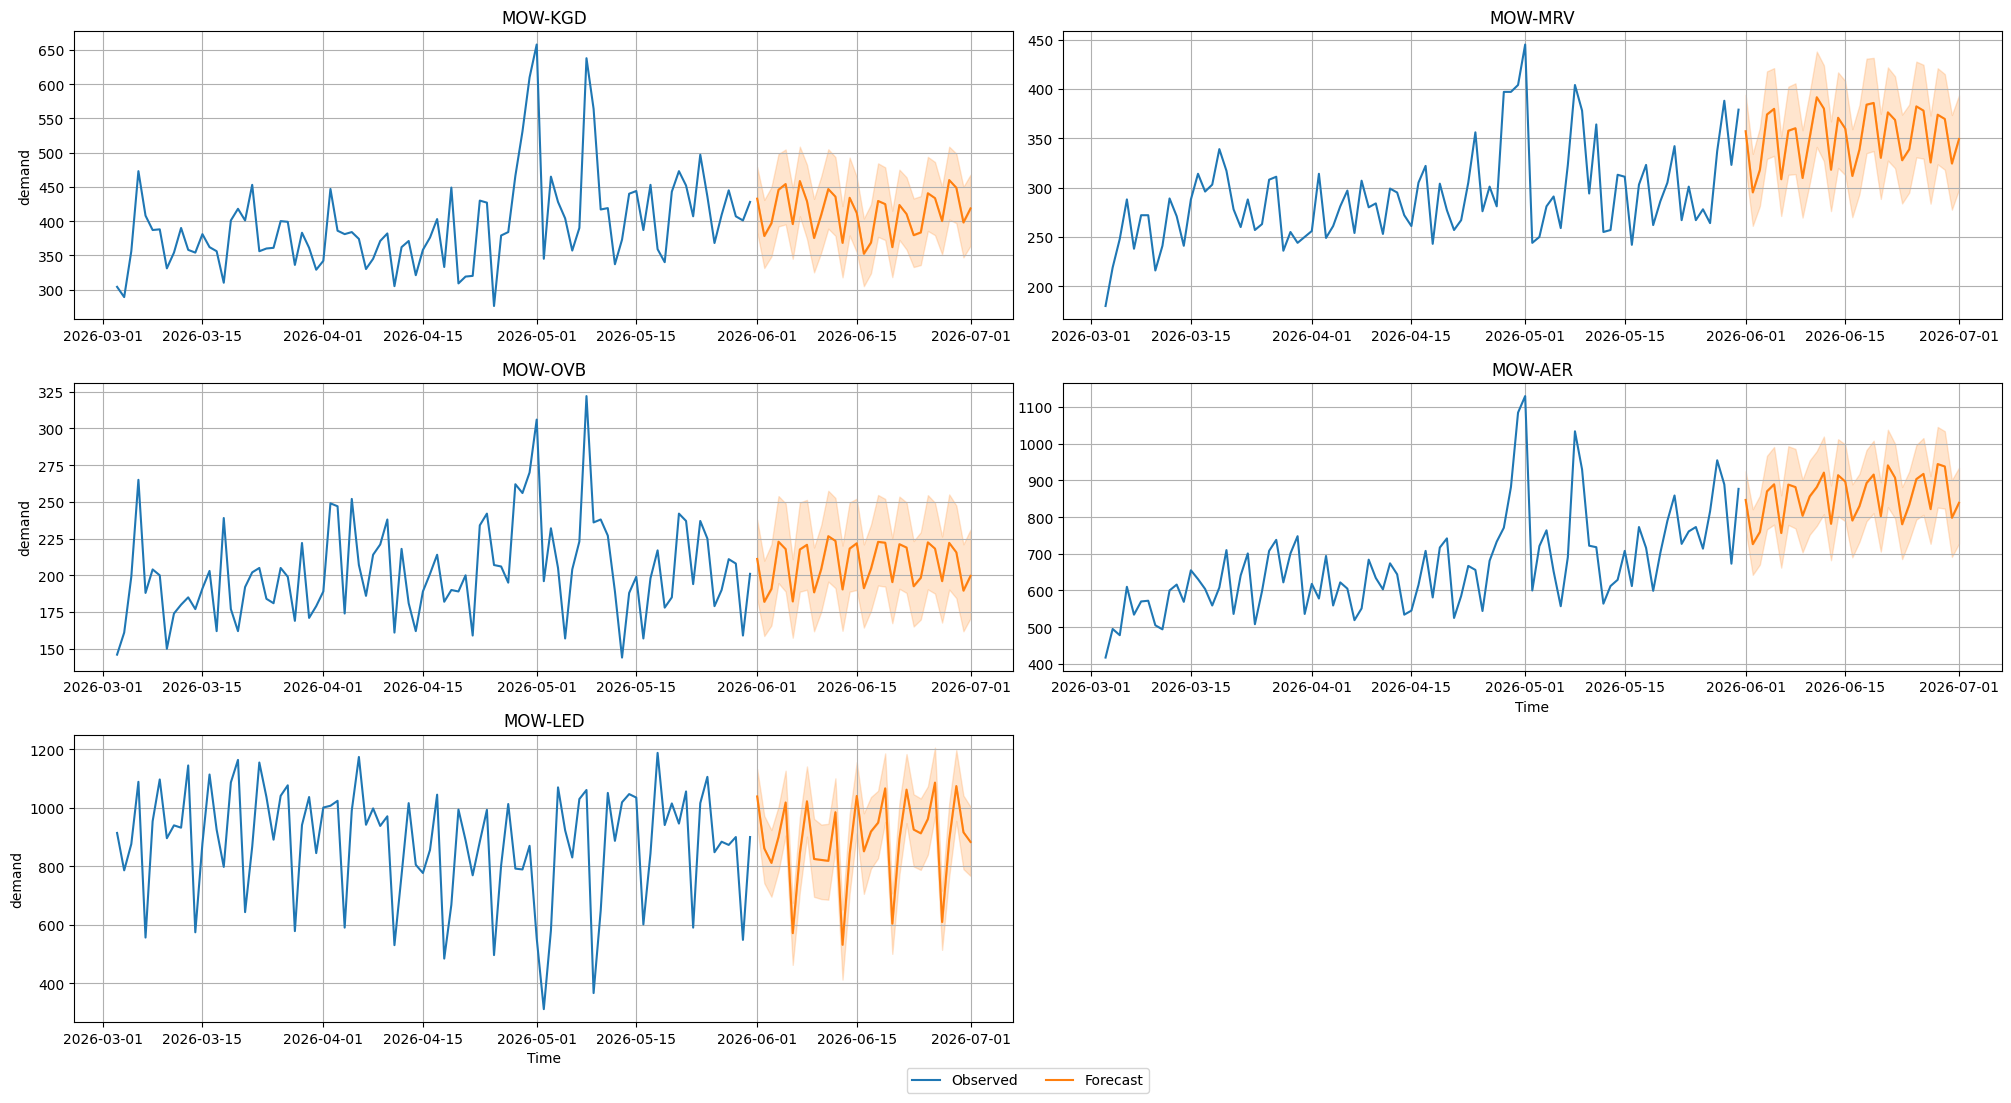

In [ ]:
# Ваш код здесь
# Подсказка: predictor.plot(история, прогноз, quantile_levels=[0.1, 0.9], max_history_length=...)
predictor.plot(history_ts, predictions, quantile_levels=[0.1, 0.9], max_history_length=90)
plt.show()

**Ваш ответ:** Как вам прогноз визуально? Похож ли он на историю? Почему интервал расширяется со временем?

Прогноз продолжает исторический ряд без резких обрывов и визуально выглядит правильно. Модель сохранила характер каждого маршрута: недельную цикличность (включая регулярные спады и скочки на каждом из маршрутов).
Чем дальше в будущее мы строим прогноз ,тем больше становится неопределенность. На ближайшие дни модель уверена сильнее и коридор узкий, а к концу месяца разброс между пессимистичным (0.1) и оптимистичным (0.9) сценариями расширяется.

## Задание 7. Как из прогноза спроса получается цена

Обязательно запустите все ячейки этого задания: в конце получится файл с прогнозом спроса и ценами, который понадобится
в части кейса Разработка.

В этом задании ничего писать не нужно, весь код уже готов. Здесь мы разберём, как сервис по вашему прогнозу спроса
подбирает цену билета.

### 7.1. Цена для одного рейса: перебор

Возьмём один рейс - Москва - Сочи, 12 июня - и медианный прогноз спроса для него (квантиль 0.5). Это спрос
**при базовой цене**. Если цену изменить, спрос тоже изменится:

```
спрос(цена) = прогноз спроса − чувствительность × (цена − базовая цена)
```

Например, у Сочи чувствительность 0.141: если поднять цену на 1 000 ₽, лететь захотят примерно на 141 человека меньше.

Продать больше билетов, чем мест в самолёте, нельзя:

```
продано = min(спрос(цена), мест в самолёте)
```

А прибыль - это то, что остаётся с каждого билета после расходов, умноженное на число проданных билетов:

```
прибыль = (цена − расходы на пассажира) × продано
```

Почему у прибыли есть максимум:
- **слишком низкая цена** - билеты раскупят, но с каждого мы заработаем мало;
- **слишком высокая цена** - с каждого билета заработаем много, но покупателей почти не останется.

Лучшая цена где-то посередине. Чтобы её найти, переберём все цены с шагом 100 ₽ и выберем ту, при которой прибыль
наибольшая.

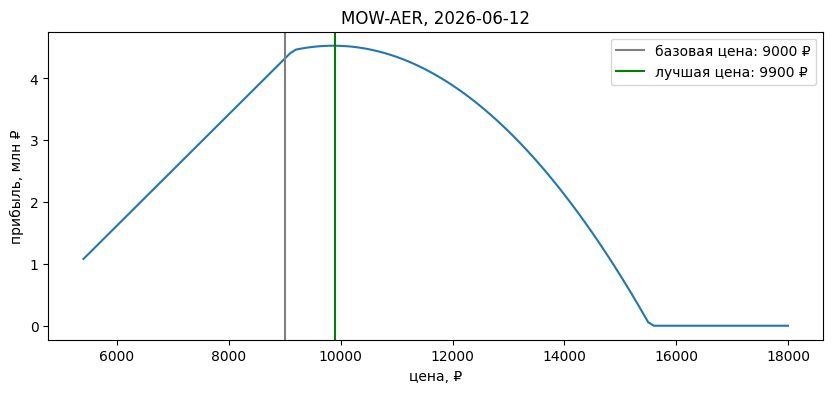

In [ ]:
schedule = pd.read_csv(DATA_DIR + "schedule.csv", parse_dates=["date"])

route, day = "MOW-AER", pd.Timestamp("2026-06-12")
info = routes[routes["route"] == route].iloc[0]                                   # параметры маршрута
seats = schedule[(schedule["route"] == route) & (schedule["date"] == day)]["seats"].iloc[0]
demand_base = predictions.loc[(route, day), "0.5"]                                # медианный прогноз спроса

prices = np.arange(info["price_min"], info["price_max"] + 1, 100)                # все цены с шагом 100 ₽
demand = np.maximum(0, demand_base - info["price_sensitivity"] * (prices - info["base_price"]))
sold = np.minimum(demand, seats)
profit = (prices - info["cost_per_passenger"]) * sold
best_price = prices[profit.argmax()]

plt.figure(figsize=(10, 4))
plt.plot(prices, profit / 1e6)
plt.axvline(info["base_price"], color="gray", label=f"базовая цена: {info['base_price']} ₽")
plt.axvline(best_price, color="green", label=f"лучшая цена: {best_price} ₽")
plt.xlabel("цена, ₽"); plt.ylabel("прибыль, млн ₽"); plt.title(f"{route}, {day.date()}")
plt.legend(); plt.show()

### 7.2. Та же цена - по формуле

Перебирать цены не обязательно: лучшую цену можно посчитать сразу, школьной математикой.

**Пока мест хватает**, прибыль зависит от цены как парабола:

```
прибыль(цена) = (цена − расходы) × (прогноз − чувствительность × (цена − базовая цена))
```

Она обращается в ноль в двух точках:
- когда цена равна расходам - с билета ничего не зарабатываем;
- когда цена так высока, что желающих не остаётся: `базовая цена + прогноз / чувствительность`.

Вершина параболы лежит ровно посередине между этими точками:

```
вершина = (расходы + базовая цена + прогноз / чувствительность) / 2
```

**Если желающих больше, чем мест**, цену выгодно поднимать, пока самолёт не начнёт пустеть: всё равно продадим все
места, но дороже. Цена, при которой самолёт ровно заполняется:

```
цена_полного_самолёта = базовая цена + (прогноз − мест) / чувствительность
```

**Лучшая цена** - большая из этих двух, но не выходящая за допустимый диапазон от `price_min` до `price_max`. Проверим,
что формула даёт то же, что и перебор (перебор шёл с шагом 100 ₽, поэтому совпадение - с точностью до 100 ₽).

In [ ]:
def optimal_price(demand_base, info, seats):
    """Лучшая цена для одного сценария спроса - по формуле, без перебора."""
    b, p0, cost = info["price_sensitivity"], info["base_price"], info["cost_per_passenger"]
    top_of_parabola = (cost + p0 + demand_base / b) / 2       # вершина параболы (мест хватает)
    full_plane = p0 + (demand_base - seats) / b                # самолёт заполнен ровно
    price = max(top_of_parabola, full_plane)
    return min(max(price, info["price_min"]), info["price_max"])   # не выходим за допустимый диапазон

print("перебор:", best_price, "₽")
print("формула:", round(optimal_price(demand_base, info, seats)), "₽")

перебор: 9900 ₽
формула: 9867 ₽


### 7.3. От квантилей спроса - к распределению цены

До сих пор мы считали цену только для медианного прогноза (квантиль 0.5). Но модель выдаёт 9 сценариев спроса,
от пессимистичного 0.1 до оптимистичного 0.9. Посчитаем лучшую цену для каждого из них.

Чем больше спрос, тем выше лучшая цена. Поэтому из 9 сценариев спроса получается 9 сценариев цены - это и есть
**распределение цены**, о котором шла речь в начале:
- если цены в разных сценариях близки, модель уверена и цену можно ставить смело;
- если разброс большой, на рейс стоит посмотреть внимательнее и выбрать менее рискованную цену.

Для каждого сценария посчитаем, сколько билетов продадим по лучшей цене и какой будет прибыль. Для сравнения - прибыль,
если оставить базовую цену.

In [ ]:
QUANTILES = ["0.1", "0.2", "0.3", "0.4", "0.5", "0.6", "0.7", "0.8", "0.9"]

rows = []
for q in QUANTILES:
    d = predictions.loc[(route, day), q]                          # спрос при базовой цене в этом сценарии
    price = optimal_price(d, info, seats)
    sold_q = min(max(0, d - info["price_sensitivity"] * (price - info["base_price"])), seats)
    sold_base = min(d, seats)                                     # продажи, если оставить базовую цену
    rows.append({
        "квантиль": q,
        "спрос при базовой цене": round(d),
        "лучшая цена, ₽": round(price),
        "продано": round(sold_q),
        "прибыль, млн ₽": round((price - info["cost_per_passenger"]) * sold_q / 1e6, 2),
        "прибыль при базовой цене, млн ₽": round((info["base_price"] - info["cost_per_passenger"]) * sold_base / 1e6, 2),
    })
pd.DataFrame(rows)

,квантиль,спрос при базовой цене,"лучшая цена, ₽",продано,"прибыль, млн ₽","прибыль при базовой цене, млн ₽"
0,0.1,808,9466,743,3.91,3.88
1,0.2,853,9624,765,4.15,4.09
2,0.3,880,9721,778,4.30,4.22
3,0.4,901,9795,789,4.41,4.32
4,0.5,921,9867,799,4.53,4.32
5,0.6,938,9928,808,4.63,4.32
6,0.7,958,9997,817,4.74,4.32
7,0.8,982,10081,829,4.88,4.32
8,0.9,1020,10216,848,5.10,4.32


### 7.4. Все рейсы и файл для сервиса

Теперь посчитаем то же самое для всех маршрутов и всех дней июня. Для каждого рейса и каждого из 9 сценариев получим
спрос при базовой цене, лучшую цену и спрос при лучшей цене. Результат сохраним в файл `my_forecast.csv`, его и нужно будет использовать в части Разработка.

Колонки файла:

| колонка | что означает |
|---|---|
| `route` | код маршрута |
| `date` | дата рейса |
| `seats` | сколько мест в самолётах |
| `0.1_base_demand` … `0.9_base_demand` | спрос при базовой цене в каждом сценарии |
| `0.1_price` … `0.9_price` | лучшая цена в каждом сценарии, ₽ |
| `0.1_price_demand` … `0.9_price_demand` | спрос при лучшей цене (без учёта ограничения по местам) |

In [ ]:
rows = []
for (route_i, day_i), forecast_row in predictions.iterrows():          # по одной строке на маршрут и день
    info_i = routes[routes["route"] == route_i].iloc[0]
    seats_i = schedule[(schedule["route"] == route_i) & (schedule["date"] == day_i)]["seats"].iloc[0]
    row = {"route": route_i, "date": day_i.strftime("%Y-%m-%d"), "seats": seats_i}
    for q in QUANTILES:
        d = forecast_row[q]
        price = optimal_price(d, info_i, seats_i)
        row[f"{q}_base_demand"] = round(d)                                                        # спрос при базовой цене
        row[f"{q}_price"] = round(price)                                                          # лучшая цена
        row[f"{q}_price_demand"] = round(max(0, d - info_i["price_sensitivity"] * (price - info_i["base_price"])))
    rows.append(row)

result = pd.DataFrame(rows)
result.to_csv("my_forecast.csv", index=False)
result.head()

,route,date,seats,0.1_base_demand,0.1_price,0.1_price_demand,0.2_base_demand,0.2_price,0.2_price_demand,0.3_base_demand,...,0.6_price_demand,0.7_base_demand,0.7_price,0.7_price_demand,0.8_base_demand,0.8_price,0.8_price_demand,0.9_base_demand,0.9_price,0.9_price_demand
0,MOW-AER,2026-06-01,900,766,9317,722,795,9419,736,814,...,769,876,9707,776,897,9780,787,925,9880,801
1,MOW-AER,2026-06-02,900,643,8879,660,671,8980,674,691,...,711,763,9307,720,789,9396,733,822,9514,749
2,MOW-AER,2026-06-03,900,670,8978,674,702,9090,689,723,...,728,800,9438,739,826,9528,751,859,9645,768
3,MOW-AER,2026-06-04,900,767,9318,722,807,9461,742,833,...,782,907,9818,792,932,9906,805,967,10029,822
4,MOW-AER,2026-06-05,900,780,9365,728,820,9509,749,848,...,792,929,9893,803,956,9989,816,991,10115,834


Посмотрим на один маршрут целиком. Сверху - спрос при базовой цене и спрос при лучшей цене вместе с числом мест
в самолётах, снизу - лучшая цена и базовая цена. Видно, как цена следует за спросом: где спрос высокий, цену поднимаем,
и желающих становится меньше.

**Результат задания:** запущенные ячейки и файл `my_forecast.csv`.

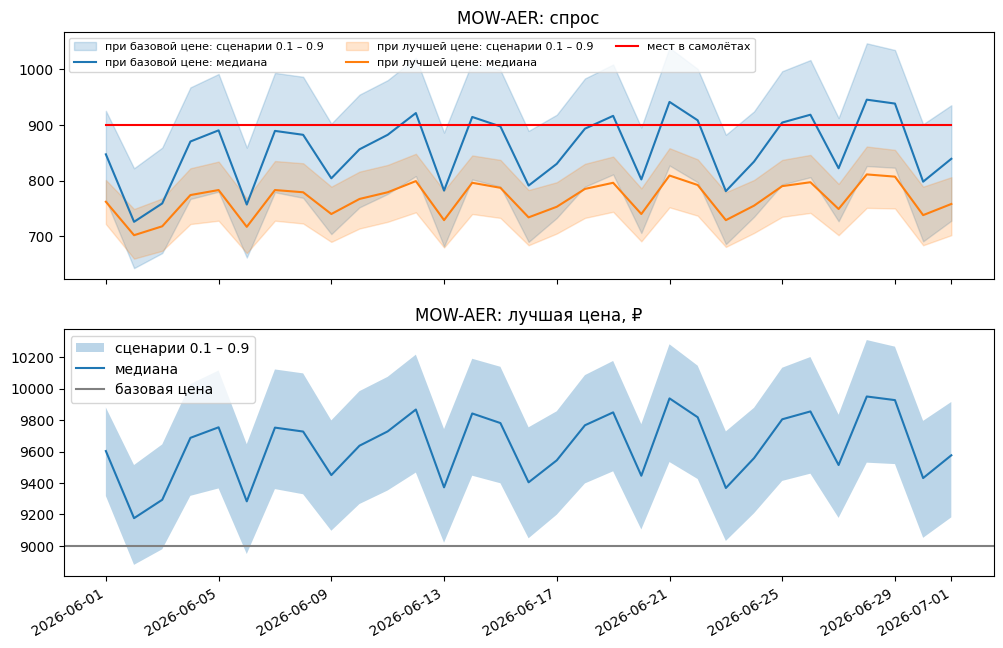

In [ ]:
one = result[result["route"] == "MOW-AER"]
dates = pd.to_datetime(one["date"])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
ax1.fill_between(dates, one["0.1_base_demand"], one["0.9_base_demand"], color="C0", alpha=0.2,
                 label="при базовой цене: сценарии 0.1 – 0.9")
ax1.plot(dates, one["0.5_base_demand"], color="C0", label="при базовой цене: медиана")
ax1.fill_between(dates, one["0.1_price_demand"], one["0.9_price_demand"], color="C1", alpha=0.2,
                 label="при лучшей цене: сценарии 0.1 – 0.9")
ax1.plot(dates, one["0.5_price_demand"], color="C1", label="при лучшей цене: медиана")
ax1.plot(dates, one["seats"], color="red", label="мест в самолётах")
ax1.set_title("MOW-AER: спрос"); ax1.legend(fontsize=8, ncol=3)

ax2.fill_between(dates, one["0.1_price"], one["0.9_price"], alpha=0.3, label="сценарии 0.1 – 0.9")
ax2.plot(dates, one["0.5_price"], label="медиана")
ax2.axhline(routes[routes["route"] == "MOW-AER"]["base_price"].iloc[0], color="gray", label="базовая цена")
ax2.set_title("MOW-AER: лучшая цена, ₽"); ax2.legend()
fig.autofmt_xdate()                                    # наклоняем подписи дат, чтобы не наезжали
plt.show()

## Готово!

Сдайте:
1. этот ноутбук с вашим кодом и ответами на вопросы;
2. файл `my_forecast.csv` из задания 7 - используйте его в части кейса Разработка.